## Examen ICCD753 Recuperación de Información

Desarrollar un sistema de recuperación de información sobre un corpus asignado. El sistema deberá indexar los documentos, recuperar y ordenar resultados mediante TF-IDF con similitud coseno y BM25, y exponer la búsqueda como un servicio web publicado en internet.

Se evaluará el servicio enviando consultas desde un cliente (p.ej. Postman) y contrastando los resultados con los juicios de relevancia (qrels) del corpus.

## 1. Importar librerias

In [78]:
import numpy as np # linear algebra
import pandas as pd 
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
import nltk
from nltk.stem import SnowballStemmer
from collections import Counter
import math
import time
import matplotlib.pyplot as plt
import seaborn as sns
import os
import pickle
import requests
import pandas as pd
import time



## 2. Importar qrels 

In [40]:
ruta = "/kaggle/input/datasets/juan1696/qrelss/"

qrels_train = pd.read_csv(
    ruta + "train.tsv",
    sep="\t"
)

qrels_dev = pd.read_csv(
    ruta + "dev.tsv",
    sep="\t"
)

qrels_test = pd.read_csv(
    ruta + "test.tsv",
    sep="\t"
)

display(qrels_train.head())
display(qrels_dev.head())
display(qrels_test.head())


,query-id,corpus-id,score
0,PLAIN-3,MED-2436,1
1,PLAIN-3,MED-2437,1
2,PLAIN-3,MED-2438,1
3,PLAIN-3,MED-2439,1
4,PLAIN-3,MED-2440,1


,query-id,corpus-id,score
0,PLAIN-1,MED-2421,2
1,PLAIN-1,MED-2422,2
2,PLAIN-1,MED-2416,2
3,PLAIN-1,MED-2423,2
4,PLAIN-1,MED-2417,2


,query-id,corpus-id,score
0,PLAIN-2,MED-2427,2
1,PLAIN-2,MED-10,2
2,PLAIN-2,MED-2429,2
3,PLAIN-2,MED-2430,2
4,PLAIN-2,MED-2431,2


## 3. Preprocesamiento y Carga

### 3.1 Importar corpus y queries de NFCorpus

En este paso importamos y lo convertimos en diccionario. 

In [23]:
df_corpus = pd.read_parquet("/kaggle/input/datasets/juan1696/nfcorpus/corpus-00000-of-00001.parquet")
df_queries = pd.read_parquet("/kaggle/input/datasets/juan1696/nfcorpus/queries-00000-of-00001.parquet")

display(df_corpus.head())
display(df_queries.head())

df1 = df_corpus.dropna(subset=["_id", "text"]).copy()
df1["texto"] = (df1["title"].fillna("")+ " "+df1["text"])
df2 = df_queries.dropna(subset=["_id", "text"]).copy()


documentos = dict(zip(
    df1["_id"],df1["text"]
))


consultas = dict(zip(
    df2["_id"],df2["text"]
))

print("Documentos:", len(documentos))
print(next(iter(documentos.items())))

print("Consultas:", len(consultas))
print(next(iter(consultas.items())))



,_id,title,text
0,MED-10,Statin Use and Breast Cancer Survival: A Natio...,"Recent studies have suggested that statins, an..."
1,MED-14,Statin use after diagnosis of breast cancer an...,BACKGROUND: Preclinical studies have shown tha...
2,MED-118,Alkylphenols in human milk and their relations...,The aims of this study were to determine the c...
3,MED-301,Methylmercury: A Potential Environmental Risk ...,Epilepsy or seizure disorder is one of the mos...
4,MED-306,Sensitivity of Continuous Performance Test (CP...,Hit Reaction Time latencies (HRT) in the Conti...


,_id,title,text
0,PLAIN-3,,Breast Cancer Cells Feed on Cholesterol
1,PLAIN-4,,Using Diet to Treat Asthma and Eczema
2,PLAIN-5,,Treating Asthma With Plants vs. Pills
3,PLAIN-6,,How Fruits and Vegetables Can Treat Asthma
4,PLAIN-7,,How Fruits and Vegetables Can Prevent Asthma


Documentos: 3633
('MED-10', 'Recent studies have suggested that statins, an established drug group in the prevention of cardiovascular mortality, could delay or prevent breast cancer recurrence but the effect on disease-specific mortality remains unclear. We evaluated risk of breast cancer death among statin users in a population-based cohort of breast cancer patients. The study cohort included all newly diagnosed breast cancer patients in Finland during 1995–2003 (31,236 cases), identified from the Finnish Cancer Registry. Information on statin use before and after the diagnosis was obtained from a national prescription database. We used the Cox proportional hazards regression method to estimate mortality among statin users with statin use as time-dependent variable. A total of 4,151 participants had used statins. During the median follow-up of 3.25 years after the diagnosis (range 0.08–9.0 years) 6,011 participants died, of which 3,619 (60.2%) was due to breast cancer. After adjustme

### 3.2 Stopwords

In [26]:
stop_words = set(ENGLISH_STOP_WORDS)

stop_words -= {"no", "not", "nor", "don't", "doesn't", "isn't", "wasn't"}

### 3.3 Procesar texto 

In [27]:
def procesar_texto(texto):
    tokens =  re.findall(r"[a-z0-9]+(?:['-][a-z0-9]+)*",texto.lower().replace("’", "'"))
    return [t for t in tokens if t not in stop_words] 


docs_tokens={}
quer_tokens={}
for docid,texto in documentos.items():   
    docs_tokens[docid] = procesar_texto(texto)
print(len(docs_tokens))

for qrid,texto in consultas.items():   
    quer_tokens[qrid] = procesar_texto(texto)
print(len(quer_tokens))


#Stemming
docs_stemming = {}
querss_stemming = {}
stemmer = SnowballStemmer("english")
for docid, tokens in docs_tokens.items():
    docs_stemming[docid] = [
        stemmer.stem(t) for t in tokens
    ]


print(next(iter(docs_stemming.items())))


for qrid, tokens in quer_tokens.items():
    querss_stemming[qrid] = [
        stemmer.stem(t) for t in tokens
    ]

3633
3237
('MED-10', ['recent', 'studi', 'suggest', 'statin', 'establish', 'drug', 'group', 'prevent', 'cardiovascular', 'mortal', 'delay', 'prevent', 'breast', 'cancer', 'recurr', 'effect', 'disease-specif', 'mortal', 'remain', 'unclear', 'evalu', 'risk', 'breast', 'cancer', 'death', 'statin', 'user', 'population-bas', 'cohort', 'breast', 'cancer', 'patient', 'studi', 'cohort', 'includ', 'newli', 'diagnos', 'breast', 'cancer', 'patient', 'finland', '1995', '2003', '31', '236', 'case', 'identifi', 'finnish', 'cancer', 'registri', 'inform', 'statin', 'use', 'diagnosi', 'obtain', 'nation', 'prescript', 'databas', 'use', 'cox', 'proport', 'hazard', 'regress', 'method', 'estim', 'mortal', 'statin', 'user', 'statin', 'use', 'time-depend', 'variabl', 'total', '4', '151', 'particip', 'use', 'statin', 'median', 'follow-up', '3', '25', 'year', 'diagnosi', 'rang', '0', '08', '9', '0', 'year', '6', '011', 'particip', 'die', '3', '619', '60', '2', 'breast', 'cancer', 'adjust', 'age', 'tumor', 'cha

## 4. Construcción indice invertido

In [33]:
#Obtener vocabulario y luego df idf a partir de un indice invertido con tf 
def indice_inv(docs_stemming):    
    indice = {}
    longitudes = {}
    for docid, tokens in docs_stemming.items():
        longitudes[docid] = len(tokens)
        for termino, tf in Counter(tokens).items():
            if termino not in indice:
                indice[termino] = {}
            indice[termino][docid] = tf       
    return indice, longitudes

indice, longitudes = indice_inv(docs_stemming)
print(next(iter(indice.items())))

def docfrec(indice):
    dfreq = {}
    for termino in indice.keys():
        dfreq[termino] = len(indice[termino])    
    return dfreq
print("="*20+"Hola")
dfreq = docfrec(indice)
print(next(iter(dfreq.items())))

def get_voc(indice):
    return set(indice.keys())

N = len(docs_stemming)

promedio_longitud = np.mean(
    list(longitudes.values())
)

vocabulario = get_voc(indice)

('recent', {'MED-10': 1, 'MED-398': 1, 'MED-712': 1, 'MED-714': 1, 'MED-721': 2, 'MED-728': 1, 'MED-745': 1, 'MED-749': 1, 'MED-756': 1, 'MED-823': 1, 'MED-839': 1, 'MED-845': 1, 'MED-872': 3, 'MED-877': 1, 'MED-898': 1, 'MED-913': 3, 'MED-944': 1, 'MED-950': 1, 'MED-966': 2, 'MED-982': 1, 'MED-985': 1, 'MED-999': 2, 'MED-1020': 1, 'MED-1042': 1, 'MED-1054': 1, 'MED-1068': 1, 'MED-1104': 1, 'MED-1105': 1, 'MED-1107': 1, 'MED-1120': 1, 'MED-1123': 1, 'MED-1126': 1, 'MED-1130': 1, 'MED-1140': 1, 'MED-1152': 1, 'MED-1171': 1, 'MED-1181': 1, 'MED-1192': 1, 'MED-1207': 2, 'MED-1208': 1, 'MED-1212': 1, 'MED-1217': 1, 'MED-1218': 1, 'MED-1220': 1, 'MED-1221': 1, 'MED-1234': 1, 'MED-1242': 1, 'MED-1257': 2, 'MED-1258': 1, 'MED-1267': 1, 'MED-1277': 1, 'MED-1282': 2, 'MED-1283': 1, 'MED-1287': 1, 'MED-1308': 1, 'MED-1309': 1, 'MED-1313': 1, 'MED-1344': 1, 'MED-1353': 1, 'MED-1358': 1, 'MED-1376': 1, 'MED-1400': 2, 'MED-1402': 1, 'MED-1420': 1, 'MED-1433': 1, 'MED-1434': 1, 'MED-1436': 4, 'MED-1

In [34]:
def calcular_idf(termino):

    return math.log(
        (N + 1) / (dfreq[termino] + 1)
    ) + 1

tfidf_docs = {}

for docid, tokens in docs_stemming.items():

    frecuencias = Counter(tokens)

    vector = {}

    for termino, tf in frecuencias.items():

        peso_tf = 1 + math.log(tf)

        peso_idf = calcular_idf(termino)

        vector[termino] = peso_tf * peso_idf

    tfidf_docs[docid] = vector

## 5. Implementación de modelos

### 5.1 TF-IDF

In [35]:
def buscar_tfidf(query_tokens, top_k=10):

    frecuencias = Counter(query_tokens)

    vector_query = {}

    for termino, tf in frecuencias.items():

        if termino in vocabulario:

            vector_query[termino] = (
                (1 + math.log(tf)) *
                calcular_idf(termino)
            )

    norma_query = math.sqrt(
        sum(p ** 2 for p in vector_query.values())
    )

    if norma_query == 0:
        return []

    candidatos = set()

    for termino in vector_query:
        candidatos.update(indice[termino].keys())

    resultados = []

    for docid in candidatos:

        producto = sum(
            peso_query * tfidf_docs[docid].get(termino, 0)
            for termino, peso_query in vector_query.items()
        )

        norma_doc = math.sqrt(
            sum(p ** 2 for p in tfidf_docs[docid].values())
        )

        if norma_doc > 0:

            similitud = producto / (
                norma_query * norma_doc
            )

            resultados.append((docid, similitud))

    resultados.sort(
        key=lambda x: x[1],
        reverse=True
    )

    return resultados[:top_k]

### 5.2 BM25

In [36]:
k1 = 1.5
b = 0.75

In [37]:
def buscar_bm25(query_tokens, top_k=10):

    frecuencias_query = Counter(query_tokens)

    candidatos = set()

    for termino in frecuencias_query:

        if termino in indice:
            candidatos.update(indice[termino].keys())

    resultados = []

    for docid in candidatos:

        score = 0

        for termino, qf in frecuencias_query.items():

            if termino not in indice:
                continue

            tf = indice[termino].get(docid, 0)

            if tf == 0:
                continue

            df = dfreq[termino]

            idf = math.log(
                1 + (N - df + 0.5) / (df + 0.5)
            )

            numerador = tf * (k1 + 1)

            denominador = tf + k1 * (
                1 - b + b * longitudes[docid] /
                promedio_longitud
            )

            score += idf * (
                numerador / denominador
            ) * qf

        resultados.append((docid, score))

    resultados.sort(
        key=lambda x: x[1],
        reverse=True
    )

    return resultados[:top_k]

### 5.3 Modelo Hibrido

In [38]:
def buscar_hibrido(query_tokens, top_k=10, alpha=0.5):

    tfidf = dict(
        buscar_tfidf(query_tokens, top_k=N)
    )

    bm25 = dict(
        buscar_bm25(query_tokens, top_k=N)
    )

    max_tfidf = max(tfidf.values(), default=0)
    max_bm25 = max(bm25.values(), default=0)

    candidatos = set(tfidf) | set(bm25)

    resultados = []

    for docid in candidatos:

        score_tfidf = (
            tfidf.get(docid, 0) / max_tfidf
            if max_tfidf > 0 else 0
        )

        score_bm25 = (
            bm25.get(docid, 0) / max_bm25
            if max_bm25 > 0 else 0
        )

        score = (
            alpha * score_tfidf +
            (1 - alpha) * score_bm25
        )

        resultados.append((docid, score))

    resultados.sort(
        key=lambda x: x[1],
        reverse=True
    )

    return resultados[:top_k]

## 6. Prueba de consultas

In [39]:
qid = next(iter(querss_stemming))

query = querss_stemming[qid]

print("CONSULTA:", consultas[qid])

print("\nTF-IDF:")
print(buscar_tfidf(query, 10))

print("\nBM25:")
print(buscar_bm25(query, 10))

print("\nHÍBRIDO:")
print(buscar_hibrido(query, 10))

CONSULTA: Breast Cancer Cells Feed on Cholesterol

TF-IDF:
[('MED-2434', 0.21623240946429173), ('MED-2774', 0.2132819817460979), ('MED-5184', 0.20877075301315673), ('MED-4759', 0.1939004101943108), ('MED-4880', 0.1933313642607664), ('MED-2427', 0.18953811472054571), ('MED-3551', 0.18865934890145117), ('MED-4117', 0.1823791675906119), ('MED-2439', 0.17859659736128292), ('MED-1249', 0.17569520153453)]

BM25:
[('MED-2434', np.float64(16.842155055613897)), ('MED-2427', np.float64(14.800476806794101)), ('MED-2774', np.float64(12.523879167841255)), ('MED-4759', np.float64(12.353420160604896)), ('MED-4880', np.float64(12.325670241455015)), ('MED-4117', np.float64(12.247330032916189)), ('MED-4536', np.float64(12.206597666076537)), ('MED-3129', np.float64(11.852717198)), ('MED-4465', np.float64(11.555502470900048)), ('MED-3447', np.float64(11.406458933126189))]

HÍBRIDO:
[('MED-2434', np.float64(1.0)), ('MED-2427', np.float64(0.8776619224766598)), ('MED-2774', np.float64(0.8649792104445182)), (

## 7. Preparar Qrels para la evaluación tomados de https://public.ukp.informatik.tu-darmstadt.de/

In [41]:
qrels_test = qrels_test.rename(columns={
    "query-id": "query_id",
    "corpus-id": "document_id"
})

qrels_test["query_id"] = qrels_test["query_id"].astype(str)
qrels_test["document_id"] = qrels_test["document_id"].astype(str)

qrels = {}

for _, row in qrels_test.iterrows():

    query_id = row["query_id"]
    document_id = row["document_id"]
    relevance = int(row["score"])

    if query_id not in qrels:
        qrels[query_id] = {}

    qrels[query_id][document_id] = relevance

print("Consultas evaluables:", len(qrels))
print("Ejemplo:", next(iter(qrels.items())))

Consultas evaluables: 323
Ejemplo: ('PLAIN-2', {'MED-2427': 2, 'MED-10': 2, 'MED-2429': 2, 'MED-2430': 2, 'MED-2431': 2, 'MED-14': 2, 'MED-2432': 2, 'MED-2428': 1, 'MED-2440': 1, 'MED-2434': 1, 'MED-2435': 1, 'MED-2436': 1, 'MED-2437': 1, 'MED-2438': 1, 'MED-2439': 1, 'MED-3597': 1, 'MED-3598': 1, 'MED-3599': 1, 'MED-4556': 1, 'MED-4559': 1, 'MED-4560': 1, 'MED-4828': 1, 'MED-4829': 1, 'MED-4830': 1})


## 7.1 Verificar cuantos qrels se encuentras en nuestro dataset de consultas

In [50]:
ids_corpus = set(documentos.keys())
ids_queries = set(consultas.keys())

ids_qrels_docs = {
    docid
    for relevancias in qrels.values()
    for docid in relevancias
}

ids_qrels_queries = set(qrels.keys())

print("Consultas presentes en queries:",
      len(ids_qrels_queries & ids_queries))

print("Documentos presentes en corpus:",
      len(ids_qrels_docs & ids_corpus))

print("Consultas sin correspondencia:",
      len(ids_queries - ids_qrels_queries))

print("Documentos sin correspondencia:",
      len(ids_qrels_docs - ids_corpus))

assert ids_qrels_queries.issubset(ids_queries)
assert ids_qrels_docs.issubset(ids_corpus)

Consultas presentes en queries: 323
Documentos presentes en corpus: 3128
Consultas sin correspondencia: 2914
Documentos sin correspondencia: 0


## 8. Implementar las métricas de evaluación

### 8.1. Precision@10

In [58]:
def precision_at_k(resultados, relevantes, k=10):

    recuperados = [
        docid for docid, score in resultados[:k]
    ]

    aciertos = sum(
        1 for docid in recuperados
        if relevantes.get(docid, 0) > 0
    )

    return aciertos / k

### 8.2. Recall@10

In [57]:
def recall_at_k(resultados, relevantes, k=10):

    recuperados = [
        docid for docid, score in resultados[:k]
    ]

    total_relevantes = sum(
        1 for relevancia in relevantes.values()
        if relevancia > 0
    )

    if total_relevantes == 0:
        return 0.0

    aciertos = sum(
        1 for docid in recuperados
        if relevantes.get(docid, 0) > 0
    )

    return aciertos / total_relevantes

### 8.3. NDCG@10

In [56]:
def ndcg_at_k(resultados, relevantes, k=10):

    def dcg(relevancias):

        return sum(
            (2 ** rel - 1) / math.log2(i + 2)
            for i, rel in enumerate(relevancias)
        )

    relevancias_recuperadas = [
        relevantes.get(docid, 0)
        for docid, score in resultados[:k]
    ]

    relevancias_ideales = sorted(
        relevantes.values(),
        reverse=True
    )[:k]

    dcg_real = dcg(relevancias_recuperadas)

    dcg_ideal = dcg(relevancias_ideales)

    if dcg_ideal == 0:
        return 0.0

    return dcg_real / dcg_ideal

## 9. Evaluar los tres modelos

In [55]:
def evaluar_modelo(nombre, modelo, qrels, k=10):

    resultados_evaluacion = []

    tiempo_inicio = time.time()

    for query_id, relevantes in qrels.items():

        # Obtener consulta procesada
        tokens_query = querss_stemming[query_id]

        # Recuperar documentos
        resultados = modelo(
            tokens_query,
            top_k=k
        )

        # Calcular métricas
        precision = precision_at_k(
            resultados,
            relevantes,
            k
        )

        recall = recall_at_k(
            resultados,
            relevantes,
            k
        )

        ndcg = ndcg_at_k(
            resultados,
            relevantes,
            k
        )

        resultados_evaluacion.append({

            "query_id": query_id,
            "Precision@10": precision,
            "Recall@10": recall,
            "NDCG@10": ndcg

        })

    tiempo_total = time.time() - tiempo_inicio

    df_resultados = pd.DataFrame(
        resultados_evaluacion
    )

    print("=" * 50)
    print("MODELO:", nombre)
    print("Consultas evaluadas:", len(df_resultados))
    print("Tiempo total:", round(tiempo_total, 4), "segundos")
    print("Tiempo promedio por consulta:",
          round(tiempo_total / len(df_resultados), 6), "segundos")
    print("=" * 50)

    return df_resultados, tiempo_total

### 9.1. Evaluar TF-IDF

In [59]:
eval_tfidf, tiempo_tfidf = evaluar_modelo(
    "TF-IDF",
    buscar_tfidf,
    qrels,
    k=10
)

display(eval_tfidf.head())

MODELO: TF-IDF
Consultas evaluadas: 323
Tiempo total: 2.2493 segundos
Tiempo promedio por consulta: 0.006964 segundos


,query_id,Precision@10,Recall@10,NDCG@10
0,PLAIN-2,0.6,0.250000,0.702337
1,PLAIN-12,0.1,0.033333,0.080070
2,PLAIN-23,0.5,0.055556,0.423300
3,PLAIN-33,0.2,0.062500,0.217520
4,PLAIN-44,0.1,0.017241,0.056571


### 9.2. Evaluar BM25

In [60]:
eval_bm25, tiempo_bm25 = evaluar_modelo(
    "BM25",
    buscar_bm25,
    qrels,
    k=10
)

display(eval_bm25.head())

MODELO: BM25
Consultas evaluadas: 323
Tiempo total: 0.3915 segundos
Tiempo promedio por consulta: 0.001212 segundos


,query_id,Precision@10,Recall@10,NDCG@10
0,PLAIN-2,0.5,0.208333,0.748368
1,PLAIN-12,0.1,0.033333,0.084606
2,PLAIN-23,0.5,0.055556,0.496664
3,PLAIN-33,0.2,0.062500,0.221626
4,PLAIN-44,0.2,0.034483,0.214544


### 9.3. Evaluar modelo híbrido

In [62]:
eval_hibrido, tiempo_hibrido = evaluar_modelo(
    "Híbrido",
    buscar_hibrido,
    qrels,
    k=10
)

display(eval_hibrido.head())

MODELO: Híbrido
Consultas evaluadas: 323
Tiempo total: 2.8597 segundos
Tiempo promedio por consulta: 0.008854 segundos


,query_id,Precision@10,Recall@10,NDCG@10
0,PLAIN-2,0.6,0.250000,0.754705
1,PLAIN-12,0.1,0.033333,0.080070
2,PLAIN-23,0.5,0.055556,0.477452
3,PLAIN-33,0.2,0.062500,0.221626
4,PLAIN-44,0.1,0.017241,0.056571


## 10. Crear la tabla comparativa

In [63]:
comparacion = pd.DataFrame({

    "Modelo": [
        "TF-IDF",
        "BM25",
        "Híbrido"
    ],

    "Precision@10": [
        eval_tfidf["Precision@10"].mean(),
        eval_bm25["Precision@10"].mean(),
        eval_hibrido["Precision@10"].mean()
    ],

    "Recall@10": [
        eval_tfidf["Recall@10"].mean(),
        eval_bm25["Recall@10"].mean(),
        eval_hibrido["Recall@10"].mean()
    ],

    "NDCG@10": [
        eval_tfidf["NDCG@10"].mean(),
        eval_bm25["NDCG@10"].mean(),
        eval_hibrido["NDCG@10"].mean()
    ],

    "Tiempo (segundos)": [
        tiempo_tfidf,
        tiempo_bm25,
        tiempo_hibrido
    ]

})

display(comparacion.round(4))

,Modelo,Precision@10,Recall@10,NDCG@10,Tiempo (segundos)
0,TF-IDF,0.2251,0.1442,0.3073,2.2493
1,BM25,0.2263,0.1400,0.3133,0.3915
2,Híbrido,0.2257,0.1440,0.3113,2.8597


### 10.1. Visualizar métricas

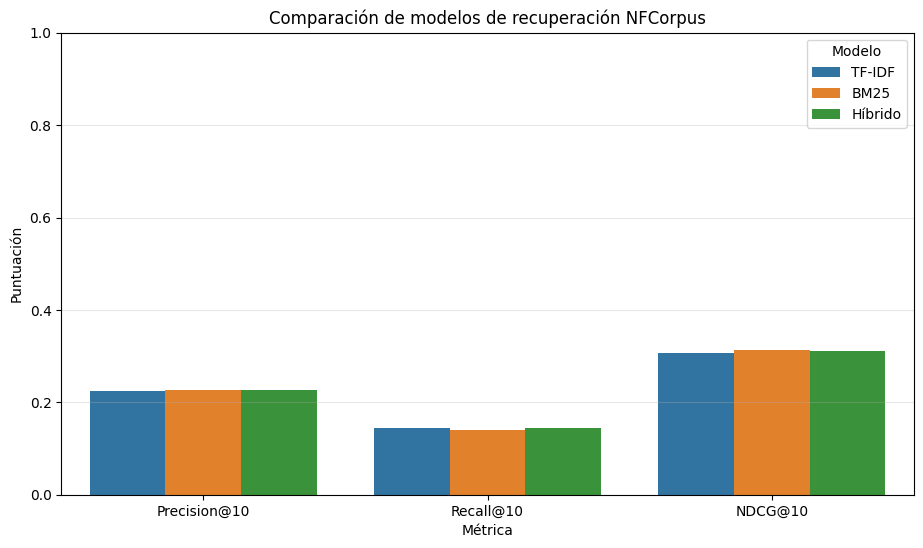

In [65]:
metricas = comparacion.melt(
    id_vars="Modelo",
    value_vars=[
        "Precision@10",
        "Recall@10",
        "NDCG@10"
    ],
    var_name="Métrica",
    value_name="Resultado"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=metricas,
    x="Métrica",
    y="Resultado",
    hue="Modelo"
)

plt.title("Comparación de modelos de recuperación NFCorpus")
plt.ylim(0, 1)
plt.ylabel("Puntuación")
plt.xlabel("Métrica")
plt.grid(axis="y", alpha=0.3)

plt.show()

### 10.2. Comparar tiempos de ejecución

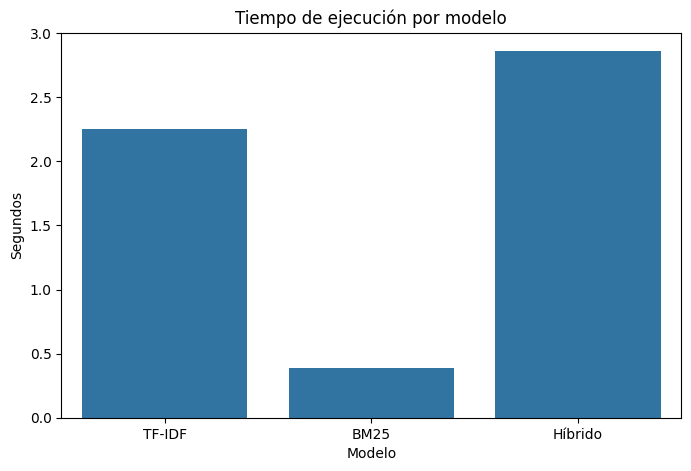

In [66]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparacion,
    x="Modelo",
    y="Tiempo (segundos)"
)

plt.title("Tiempo de ejecución por modelo")
plt.ylabel("Segundos")
plt.xlabel("Modelo")

plt.show()

## 11. Analizar cuál modelo obtuvo mejores resultados

In [68]:
for metrica in [
    "Precision@10",
    "Recall@10",
    "NDCG@10"
]:

    mejor = comparacion.loc[
        comparacion[metrica].idxmax()
    ]

    print(
        f"Mejor modelo en {metrica}: "
        f"{mejor['Modelo']} "
        f"({mejor[metrica]:.4f})"
    )

Mejor modelo en Precision@10: BM25 (0.2263)
Mejor modelo en Recall@10: TF-IDF (0.1442)
Mejor modelo en NDCG@10: BM25 (0.3133)


## 12. Guardado de las evaluaciones

In [69]:
os.makedirs("/kaggle/working/resultados", exist_ok=True)

eval_tfidf.to_csv(
    "/kaggle/working/resultados/evaluacion_tfidf.csv",
    index=False
)

eval_bm25.to_csv(
    "/kaggle/working/resultados/evaluacion_bm25.csv",
    index=False
)

eval_hibrido.to_csv(
    "/kaggle/working/resultados/evaluacion_hibrido.csv",
    index=False
)

comparacion.to_csv(
    "/kaggle/working/resultados/comparacion_modelos.csv",
    index=False
)

print("Todos los resultados fueron guardados.")

Todos los resultados fueron guardados.


### 12.1 Guardado del modelo 

In [71]:
os.makedirs("/kaggle/working/servicio_nfcorpus/datos", exist_ok=True)

# Guardar información completa de los documentos
documentos_info = {}

for _, row in df1.iterrows():

    documentos_info[str(row["_id"])] = {
        "title": row["title"],
        "text": row["text"]
    }

# Calcular normas de los vectores TF-IDF
normas_docs = {}

for docid, vector in tfidf_docs.items():

    normas_docs[docid] = math.sqrt(
        sum(peso ** 2 for peso in vector.values())
    )

# Empaquetar todas las estructuras
modelo_datos = {

    "indice": indice,
    "longitudes": longitudes,
    "dfreq": dfreq,
    "tfidf_docs": tfidf_docs,
    "normas_docs": normas_docs,

    "documentos_info": documentos_info,

    "N": N,
    "promedio_longitud": promedio_longitud,

    "stop_words": list(stop_words),

    "k1": k1,
    "b": b
}

ruta_modelo = (
    "/kaggle/working/servicio_nfcorpus/"
    "datos/modelo.pkl"
)

with open(ruta_modelo, "wb") as archivo:

    pickle.dump(
        modelo_datos,
        archivo,
        protocol=pickle.HIGHEST_PROTOCOL
    )

print("Modelo exportado correctamente.")
print("Documentos:", len(documentos_info))
print("Términos:", len(indice))
print("Archivo:", ruta_modelo)

Modelo exportado correctamente.
Documentos: 3633
Términos: 24532
Archivo: /kaggle/working/servicio_nfcorpus/datos/modelo.pkl


## 13. Creación de archivos para el servicio

### 13.1 Motor.py


In [72]:
%%writefile /kaggle/working/servicio_nfcorpus/motor.py


import re
import math

from collections import Counter


class MotorRecuperacion:

    def __init__(self, datos):

        self.indice = datos["indice"]
        self.longitudes = datos["longitudes"]
        self.dfreq = datos["dfreq"]

        self.tfidf_docs = datos["tfidf_docs"]
        self.normas_docs = datos["normas_docs"]

        self.documentos_info = datos["documentos_info"]

        self.N = datos["N"]
        self.promedio_longitud = datos["promedio_longitud"]

        self.stop_words = set(datos["stop_words"])

        self.k1 = datos["k1"]
        self.b = datos["b"]

        self.vocabulario = set(self.indice.keys())

    # --------------------------------
    # PREPROCESAMIENTO
    # --------------------------------

    def procesar_texto(self, texto):

        tokens = re.findall(
            r"[a-z0-9]+(?:['-][a-z0-9]+)*",
            texto.lower().replace("’", "'")
        )

        tokens = [
            t for t in tokens
            if t not in self.stop_words
        ]

        from nltk.stem import SnowballStemmer

        stemmer = SnowballStemmer("english")

        return [stemmer.stem(t) for t in tokens]

    # --------------------------------
    # TF-IDF
    # --------------------------------

    def calcular_idf(self, termino):

        return math.log(
            (self.N + 1) / (self.dfreq[termino] + 1)
        ) + 1

    def buscar_tfidf(self, query_tokens, top_k=10):

        frecuencias = Counter(query_tokens)

        vector_query = {}

        for termino, tf in frecuencias.items():

            if termino in self.vocabulario:

                vector_query[termino] = (
                    (1 + math.log(tf)) *
                    self.calcular_idf(termino)
                )

        norma_query = math.sqrt(
            sum(p ** 2 for p in vector_query.values())
        )

        if norma_query == 0:
            return []

        candidatos = set()

        for termino in vector_query:

            candidatos.update(
                self.indice[termino].keys()
            )

        resultados = []

        for docid in candidatos:

            producto = sum(
                peso_query *
                self.tfidf_docs[docid].get(termino, 0)

                for termino, peso_query in vector_query.items()
            )

            norma_doc = self.normas_docs[docid]

            if norma_doc > 0:

                similitud = producto / (
                    norma_query * norma_doc
                )

                resultados.append((docid, similitud))

        resultados.sort(
            key=lambda x: x[1],
            reverse=True
        )

        return resultados[:top_k]

    # --------------------------------
    # BM25
    # --------------------------------

    def buscar_bm25(self, query_tokens, top_k=10):

        frecuencias_query = Counter(query_tokens)

        candidatos = set()

        for termino in frecuencias_query:

            if termino in self.indice:

                candidatos.update(
                    self.indice[termino].keys()
                )

        resultados = []

        for docid in candidatos:

            score = 0.0

            for termino, qf in frecuencias_query.items():

                if termino not in self.indice:
                    continue

                tf = self.indice[termino].get(docid, 0)

                if tf == 0:
                    continue

                df = self.dfreq[termino]

                idf = math.log(
                    1 + (
                        self.N - df + 0.5
                    ) / (
                        df + 0.5
                    )
                )

                numerador = tf * (self.k1 + 1)

                denominador = tf + self.k1 * (
                    1 - self.b +
                    self.b * self.longitudes[docid] /
                    self.promedio_longitud
                )

                score += idf * (
                    numerador / denominador
                ) * qf

            if score > 0:

                resultados.append((docid, score))

        resultados.sort(
            key=lambda x: x[1],
            reverse=True
        )

        return resultados[:top_k]

    # --------------------------------
    # MODELO HIBRIDO
    # --------------------------------

    def buscar_hibrido(
        self,
        query_tokens,
        top_k=10,
        alpha=0.5
    ):

        tfidf = dict(
            self.buscar_tfidf(query_tokens, self.N)
        )

        bm25 = dict(
            self.buscar_bm25(query_tokens, self.N)
        )

        max_tfidf = max(tfidf.values(), default=0)
        max_bm25 = max(bm25.values(), default=0)

        candidatos = set(tfidf) | set(bm25)

        resultados = []

        for docid in candidatos:

            score_tfidf = (
                tfidf.get(docid, 0) / max_tfidf
                if max_tfidf > 0 else 0
            )

            score_bm25 = (
                bm25.get(docid, 0) / max_bm25
                if max_bm25 > 0 else 0
            )

            score = (
                alpha * score_tfidf +
                (1 - alpha) * score_bm25
            )

            resultados.append((docid, score))

        resultados.sort(
            key=lambda x: x[1],
            reverse=True
        )

        return resultados[:top_k]

    # --------------------------------
    # BUSQUEDA GENERAL
    # --------------------------------

    def buscar(
        self,
        query,
        modelo="bm25",
        top_k=10,
        alpha=0.5
    ):

        tokens = self.procesar_texto(query)

        if modelo == "tfidf":

            resultados = self.buscar_tfidf(
                tokens, top_k
            )

        elif modelo == "bm25":

            resultados = self.buscar_bm25(
                tokens, top_k
            )

        elif modelo == "hibrido":

            resultados = self.buscar_hibrido(
                tokens, top_k, alpha
            )

        else:

            raise ValueError("Modelo no válido")

        respuesta = []

        for posicion, (docid, score) in enumerate(
            resultados, 1
        ):

            documento = self.documentos_info.get(
                docid, {}
            )

            respuesta.append({

                "rank": posicion,
                "document_id": docid,
                "title": documento.get("title", ""),
                "text": documento.get("text", ""),
                "score": round(float(score), 6)

            })

        return respuesta



Writing /kaggle/working/servicio_nfcorpus/motor.py


### 13.2 app.py


In [74]:
%%writefile /kaggle/working/servicio_nfcorpus/app.py


import pickle
import time

import pickle
import time

from pathlib import Path
from contextlib import asynccontextmanager
from typing import Literal

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

from motor import MotorRecuperacion


# --------------------------------
# CARGAR MODELO
# --------------------------------

BASE_DIR = Path(__file__).resolve().parent

RUTA_MODELO = BASE_DIR / "datos" / "modelo.pkl"

motor = None


@asynccontextmanager
async def lifespan(app: FastAPI):

    global motor

    with open(RUTA_MODELO, "rb") as archivo:

        datos = pickle.load(archivo)

    motor = MotorRecuperacion(datos)

    print("Motor de recuperación cargado.")
    print("Documentos:", motor.N)

    yield

    motor = None


app = FastAPI(
    title="NFCorpus Information Retrieval API",
    description=(
        "Servicio REST para recuperación de documentos "
        "científicos utilizando TF-IDF, BM25 e híbrido."
    ),
    version="1.0.0",
    lifespan=lifespan
)


# --------------------------------
# MODELO DE PETICION
# --------------------------------

class SearchRequest(BaseModel):

    query: str = Field(
        min_length=1,
        max_length=2000,
        description="Consulta del usuario"
    )

    model: Literal[
        "tfidf",
        "bm25",
        "hibrido"
    ] = "bm25"

    top_k: int = Field(
        default=10,
        ge=1,
        le=100
    )

    alpha: float = Field(
        default=0.5,
        ge=0,
        le=1
    )


# --------------------------------
# ENDPOINT HEALTH
# --------------------------------

@app.get("/health")
def health():

    return {

        "status": "ok" if motor is not None else "loading",

        "service": "NFCorpus Information Retrieval API",

        "models": [
            "tfidf",
            "bm25",
            "hibrido"
        ],

        "documents": motor.N if motor else 0

    }


# --------------------------------
# ENDPOINT SEARCH
# --------------------------------

@app.post("/search")
def search(request: SearchRequest):

    if motor is None:

        raise HTTPException(
            status_code=503,
            detail="El motor todavía no está disponible."
        )

    inicio = time.perf_counter()

    try:

        resultados = motor.buscar(
            query=request.query,
            modelo=request.model,
            top_k=request.top_k,
            alpha=request.alpha
        )

    except Exception as e:

        raise HTTPException(
            status_code=500,
            detail=f"Error durante la recuperación: {str(e)}"
        )

    tiempo = time.perf_counter() - inicio

    return {

        "query": request.query,

        "model": request.model,

        "top_k": request.top_k,

        "total_results": len(resultados),

        "execution_time_ms": round(tiempo * 1000, 3),

        "results": resultados

    }



import re
import math

from collections import Counter


class MotorRecuperacion:

    def __init__(self, datos):

        self.indice = datos["indice"]
        self.longitudes = datos["longitudes"]
        self.dfreq = datos["dfreq"]

        self.tfidf_docs = datos["tfidf_docs"]
        self.normas_docs = datos["normas_docs"]

        self.documentos_info = datos["documentos_info"]

        self.N = datos["N"]
        self.promedio_longitud = datos["promedio_longitud"]

        self.stop_words = set(datos["stop_words"])

        self.k1 = datos["k1"]
        self.b = datos["b"]

        self.vocabulario = set(self.indice.keys())

    # --------------------------------
    # PREPROCESAMIENTO
    # --------------------------------

    def procesar_texto(self, texto):

        tokens = re.findall(
            r"[a-z0-9]+(?:['-][a-z0-9]+)*",
            texto.lower().replace("’", "'")
        )

        tokens = [
            t for t in tokens
            if t not in self.stop_words
        ]

        from nltk.stem import SnowballStemmer

        stemmer = SnowballStemmer("english")

        return [stemmer.stem(t) for t in tokens]

    # --------------------------------
    # TF-IDF
    # --------------------------------

    def calcular_idf(self, termino):

        return math.log(
            (self.N + 1) / (self.dfreq[termino] + 1)
        ) + 1

    def buscar_tfidf(self, query_tokens, top_k=10):

        frecuencias = Counter(query_tokens)

        vector_query = {}

        for termino, tf in frecuencias.items():

            if termino in self.vocabulario:

                vector_query[termino] = (
                    (1 + math.log(tf)) *
                    self.calcular_idf(termino)
                )

        norma_query = math.sqrt(
            sum(p ** 2 for p in vector_query.values())
        )

        if norma_query == 0:
            return []

        candidatos = set()

        for termino in vector_query:

            candidatos.update(
                self.indice[termino].keys()
            )

        resultados = []

        for docid in candidatos:

            producto = sum(
                peso_query *
                self.tfidf_docs[docid].get(termino, 0)

                for termino, peso_query in vector_query.items()
            )

            norma_doc = self.normas_docs[docid]

            if norma_doc > 0:

                similitud = producto / (
                    norma_query * norma_doc
                )

                resultados.append((docid, similitud))

        resultados.sort(
            key=lambda x: x[1],
            reverse=True
        )

        return resultados[:top_k]

    # --------------------------------
    # BM25
    # --------------------------------

    def buscar_bm25(self, query_tokens, top_k=10):

        frecuencias_query = Counter(query_tokens)

        candidatos = set()

        for termino in frecuencias_query:

            if termino in self.indice:

                candidatos.update(
                    self.indice[termino].keys()
                )

        resultados = []

        for docid in candidatos:

            score = 0.0

            for termino, qf in frecuencias_query.items():

                if termino not in self.indice:
                    continue

                tf = self.indice[termino].get(docid, 0)

                if tf == 0:
                    continue

                df = self.dfreq[termino]

                idf = math.log(
                    1 + (
                        self.N - df + 0.5
                    ) / (
                        df + 0.5
                    )
                )

                numerador = tf * (self.k1 + 1)

                denominador = tf + self.k1 * (
                    1 - self.b +
                    self.b * self.longitudes[docid] /
                    self.promedio_longitud
                )

                score += idf * (
                    numerador / denominador
                ) * qf

            if score > 0:

                resultados.append((docid, score))

        resultados.sort(
            key=lambda x: x[1],
            reverse=True
        )

        return resultados[:top_k]

    # --------------------------------
    # MODELO HIBRIDO
    # --------------------------------

    def buscar_hibrido(
        self,
        query_tokens,
        top_k=10,
        alpha=0.5
    ):

        tfidf = dict(
            self.buscar_tfidf(query_tokens, self.N)
        )

        bm25 = dict(
            self.buscar_bm25(query_tokens, self.N)
        )

        max_tfidf = max(tfidf.values(), default=0)
        max_bm25 = max(bm25.values(), default=0)

        candidatos = set(tfidf) | set(bm25)

        resultados = []

        for docid in candidatos:

            score_tfidf = (
                tfidf.get(docid, 0) / max_tfidf
                if max_tfidf > 0 else 0
            )

            score_bm25 = (
                bm25.get(docid, 0) / max_bm25
                if max_bm25 > 0 else 0
            )

            score = (
                alpha * score_tfidf +
                (1 - alpha) * score_bm25
            )

            resultados.append((docid, score))

        resultados.sort(
            key=lambda x: x[1],
            reverse=True
        )

        return resultados[:top_k]

    # --------------------------------
    # BUSQUEDA GENERAL
    # --------------------------------

    def buscar(
        self,
        query,
        modelo="bm25",
        top_k=10,
        alpha=0.5
    ):

        tokens = self.procesar_texto(query)

        if modelo == "tfidf":

            resultados = self.buscar_tfidf(
                tokens, top_k
            )

        elif modelo == "bm25":

            resultados = self.buscar_bm25(
                tokens, top_k
            )

        elif modelo == "hibrido":

            resultados = self.buscar_hibrido(
                tokens, top_k, alpha
            )

        else:

            raise ValueError("Modelo no válido")

        respuesta = []

        for posicion, (docid, score) in enumerate(
            resultados, 1
        ):

            documento = self.documentos_info.get(
                docid, {}
            )

            respuesta.append({

                "rank": posicion,
                "document_id": docid,
                "title": documento.get("title", ""),
                "text": documento.get("text", ""),
                "score": round(float(score), 6)

            })

        return respuesta



fastapi
uvicorn[standard]
pydantic
nltk
numpy


from pathlib import Path
from contextlib import asynccontextmanager
from typing import Literal

from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

from motor import MotorRecuperacion


# --------------------------------
# CARGAR MODELO
# --------------------------------

BASE_DIR = Path(__file__).resolve().parent

RUTA_MODELO = BASE_DIR / "datos" / "modelo.pkl"

motor = None


@asynccontextmanager
async def lifespan(app: FastAPI):

    global motor

    with open(RUTA_MODELO, "rb") as archivo:

        datos = pickle.load(archivo)

    motor = MotorRecuperacion(datos)

    print("Motor de recuperación cargado.")
    print("Documentos:", motor.N)

    yield

    motor = None


app = FastAPI(
    title="NFCorpus Information Retrieval API",
    description=(
        "Servicio REST para recuperación de documentos "
        "científicos utilizando TF-IDF, BM25 e híbrido."
    ),
    version="1.0.0",
    lifespan=lifespan
)


# --------------------------------
# MODELO DE PETICION
# --------------------------------

class SearchRequest(BaseModel):

    query: str = Field(
        min_length=1,
        max_length=2000,
        description="Consulta del usuario"
    )

    model: Literal[
        "tfidf",
        "bm25",
        "hibrido"
    ] = "bm25"

    top_k: int = Field(
        default=10,
        ge=1,
        le=100
    )

    alpha: float = Field(
        default=0.5,
        ge=0,
        le=1
    )


# --------------------------------
# ENDPOINT HEALTH
# --------------------------------

@app.get("/health")
def health():

    return {

        "status": "ok" if motor is not None else "loading",

        "service": "NFCorpus Information Retrieval API",

        "models": [
            "tfidf",
            "bm25",
            "hibrido"
        ],

        "documents": motor.N if motor else 0

    }


# --------------------------------
# ENDPOINT SEARCH
# --------------------------------

@app.post("/search")
def search(request: SearchRequest):

    if motor is None:

        raise HTTPException(
            status_code=503,
            detail="El motor todavía no está disponible."
        )

    inicio = time.perf_counter()

    try:

        resultados = motor.buscar(
            query=request.query,
            modelo=request.model,
            top_k=request.top_k,
            alpha=request.alpha
        )

    except Exception as e:

        raise HTTPException(
            status_code=500,
            detail=f"Error durante la recuperación: {str(e)}"
        )

    tiempo = time.perf_counter() - inicio

    return {

        "query": request.query,

        "model": request.model,

        "top_k": request.top_k,

        "total_results": len(resultados),

        "execution_time_ms": round(tiempo * 1000, 3),

        "results": resultados

    }


Overwriting /kaggle/working/servicio_nfcorpus/app.py


### 13.3 Requirements.txt

In [75]:
%%writefile /kaggle/working/servicio_nfcorpus/requirements.txt

fastapi
uvicorn[standard]
pydantic
nltk
numpy


Writing /kaggle/working/servicio_nfcorpus/requirements.txt


### 14 Prueba local

In [76]:
import sys

sys.path.insert(
    0,
    "/kaggle/working/servicio_nfcorpus"
)

from motor import MotorRecuperacion

with open(ruta_modelo, "rb") as archivo:
    datos = pickle.load(archivo)

motor_prueba = MotorRecuperacion(datos)

resultados = motor_prueba.buscar(
    query="What are the health benefits of omega 3?",
    modelo="bm25",
    top_k=5
)

for resultado in resultados:

    print("ID:", resultado["document_id"])
    print("Título:", resultado["title"])
    print("Score:", resultado["score"])
    print("-" * 50)

ID: MED-5098
Título: A risk-benefit analysis of French high fish consumption: a QALY approach.
Score: 14.121947
--------------------------------------------------
ID: MED-4699
Título: Ageing and eating.
Score: 9.911644
--------------------------------------------------
ID: MED-4994
Título: Who benefits most from the cardioprotective properties of alcohol consumption--health freaks or couch potatoes?
Score: 8.764709
--------------------------------------------------
ID: MED-4603
Título: Reductions in Cardiovascular Disease Projected from Modest Reductions in Dietary Salt
Score: 8.68617
--------------------------------------------------
ID: MED-5301
Título: Reductions in Cardiovascular Disease Projected from Modest Reductions in Dietary Salt
Score: 8.68617
--------------------------------------------------


## 15. Empaquetado del servicio

In [77]:
import shutil

shutil.make_archive(
    "/kaggle/working/servicio_nfcorpus",
    "zip",
    "/kaggle/working/servicio_nfcorpus"
)

print("Servicio empaquetado.")

Servicio empaquetado.
